In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

In [2]:
# HELPER FUNCTIONS
# blank correction
def blank_correction(df: pd.DataFrame, blank_wells: list[str]) -> pd.DataFrame:
    blank_series = df[blank_wells].mean(axis=1)
    return df.drop(columns=blank_wells).sub(blank_series, axis=0)

In [ ]:
# load data
df = pd.read_csv('OG7_BCA1_130226.CSV', delimiter=',', skiprows=5)

# delete line 1, 3 and columns after C01
df = df.drop(df.index[[0, 2]])
df = df.loc[:, :'C03']
df = df.apply(pd.to_numeric, errors="coerce")

In [ ]:
conc_mugmL = {
    0: ['A01', 'A02', 'A03'],
    25: ['A04', 'A05', 'A06'],
    125: ['A07', 'A08', 'A09'],
    250: ['A10', 'A11', 'A12'],
    500: ['B01', 'B02', 'B03'],
    750: ['B04', 'B05', 'B06'],
    1000: ['B07', 'B08', 'B09'],
    1500: ['B10', 'B11', 'B12'],
    2000: ['C01', 'C02', 'C03']
}

df_values = df.drop(columns=['Raw Data (562)'], errors='ignore').copy()

# ensure numeric
df_values = df_values.apply(pd.to_numeric, errors="coerce")

# blank-correct standards plate
df_corr = blank_correction(df_values, ['A01', 'A02', 'A03'])

# long format from corrected data
df_long = df_corr.melt(var_name='Well', value_name='Absorbance_corr')

# map wells -> concentration
well_to_conc = {well: conc for conc, wells in conc_mugmL.items() for well in wells}
df_long['Concentration'] = df_long['Well'].map(well_to_conc)

# keep only standard wells + valid numbers
df_long = df_long.dropna(subset=['Concentration', 'Absorbance_corr'])

# average replicates
df_cal = df_long.groupby('Concentration', as_index=False)['Absorbance_corr'].mean()

In [6]:
# linear regression
x = df_cal['Concentration']
y = df_cal['Absorbance_corr']

slope, intercept, r_value, p_value, std_err = linregress(x, y)

print("Slope:", slope)
print("Intercept:", intercept)
print("R²:", r_value**2)

Slope: 0.0010759827886111873
Intercept: 0.14667156458848296
R²: 0.9919246246860535


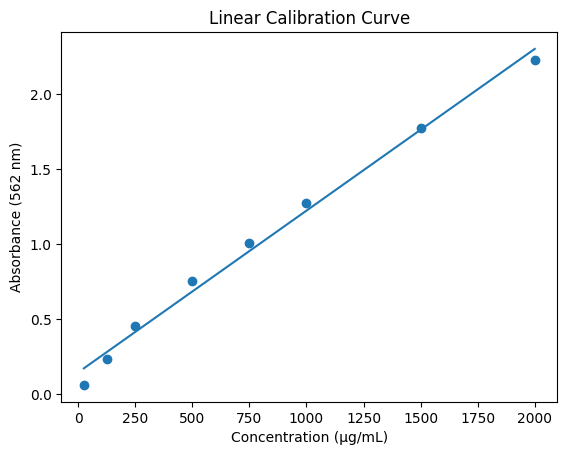

In [7]:
# plot
plt.scatter(x, y)
plt.plot(x, intercept + slope*x)

plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance (562 nm)")
plt.title("Linear Calibration Curve")

plt.show()